# Визначення дефектів асфальту 

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

OUTPUT_DIR = Path(".")

In [31]:
# A simple route in map-pixel coordinates.
# The map itself will be generated later using the same coordinate system.
route_waypoints = np.array([
    [305, 690],
    [300, 605],
    [340, 400],
    [360, 310],
    [280, 260]
], dtype=float)

sampling_hz = 10
duration_seconds = 180
n_samples = duration_seconds * sampling_hz
timestamps = np.arange(n_samples) / sampling_hz

# Interpolate along the route so the vehicle travels smoothly through all waypoints.
segment_lengths = np.linalg.norm(np.diff(route_waypoints, axis=0), axis=1)
cumulative = np.concatenate([[0], np.cumsum(segment_lengths)])
route_progress = np.linspace(0, cumulative[-1], n_samples)

x_positions = np.interp(route_progress, cumulative, route_waypoints[:, 0])
y_positions = np.interp(route_progress, cumulative, route_waypoints[:, 1])

# Define several synthetic potholes by approximate route progress (0..1).
pothole_progress = np.array([0.13, 0.31, 0.49, 0.72, 0.88])
pothole_indices = [
    int(np.argmin(np.abs(route_progress - p * cumulative[-1])))
    for p in pothole_progress
]

# Base phone accelerometer signal.
# Z is treated as the dominant vertical axis for this synthetic example.
accel_x = rng.normal(0, 0.10, n_samples)
accel_y = rng.normal(0, 0.12, n_samples)
accel_z = 9.81 + rng.normal(0, 0.16, n_samples)

# Add low-amplitude road vibration across the whole journey.
road_wave = 0.12 * np.sin(2 * np.pi * 2.0 * timestamps)
accel_z += road_wave

# Add a few ordinary small bumps (not labelled as potholes).
for idx in rng.choice(np.arange(30, n_samples - 30), size=12, replace=False):
    width = 8
    offsets = np.arange(-width, width + 1)
    valid = (idx + offsets >= 0) & (idx + offsets < n_samples)
    offsets = offsets[valid]
    pulse = 0.45 * np.exp(-np.abs(offsets) / 3.0) * np.cos(2 * np.pi * offsets / 5)
    accel_z[idx + offsets] += pulse

# Pothole impacts: stronger damped oscillations lasting roughly 1.5 seconds.
ground_truth = np.zeros(n_samples, dtype=int)
for idx in pothole_indices:
    half_window = 12
    offsets = np.arange(-half_window, half_window + 1)
    valid = (idx + offsets >= 0) & (idx + offsets < n_samples)
    offsets = offsets[valid]
    # Damped oscillation; each event has slightly different amplitude and frequency.
    amplitude = rng.uniform(2.0, 3.2)
    frequency = rng.uniform(2.2, 3.5)
    damping = rng.uniform(0.18, 0.28)
    pulse = amplitude * np.exp(-damping * np.abs(offsets)) * np.cos(
        2 * np.pi * frequency * offsets / sampling_hz
    )
    accel_z[idx + offsets] += pulse
    accel_x[idx + offsets] += 0.25 * pulse * rng.choice([-1, 1])
    accel_y[idx + offsets] += 0.18 * pulse
    ground_truth[idx + offsets] = 1

# Combined oscillation magnitude relative to gravity.
# This is a simple proxy feature, not a full orientation-independent sensor fusion solution.
accel_norm = np.sqrt(accel_x**2 + accel_y**2 + accel_z**2)
vibration = np.abs(accel_norm - 9.81)

data = pd.DataFrame({
    "timestamp": timestamps,
    "x": x_positions,
    "y": y_positions,
    "accel_x": accel_x,
    "accel_y": accel_y,
    "accel_z": accel_z,
    "vibration": vibration,
    "is_pothole": ground_truth
})

print(f"Generated {len(data):,} observations")
print(f"Sampling frequency: {sampling_hz} Hz")
print(f"Ground-truth pothole events: {len(pothole_indices)}")
data.head()


Generated 1,800 observations
Sampling frequency: 10 Hz
Ground-truth pothole events: 5


,timestamp,x,y,accel_x,accel_y,accel_z,vibration,is_pothole
0,0.0,305.000000,690.000000,0.042602,0.179402,9.874928,0.066649,0
1,0.1,304.984314,689.733341,-0.069069,-0.202093,10.009753,0.202032,0
2,0.2,304.968628,689.466683,0.085925,0.181661,9.876153,0.068197,0
3,0.3,304.952943,689.200024,0.023307,0.222050,9.613370,0.194038,0
4,0.4,304.937257,688.933365,-0.006917,0.068168,9.933972,0.124208,0


In [32]:
window = 7  # 0.7 seconds at 10 Hz

features = pd.DataFrame(index=data.index)
features["vibration"] = data["vibration"]
features["rolling_mean"] = data["vibration"].rolling(window, min_periods=1).mean()
features["rolling_std"] = data["vibration"].rolling(window, min_periods=1).std().fillna(0)
features["rolling_max"] = data["vibration"].rolling(window, min_periods=1).max()
features["rolling_rms"] = np.sqrt(
    (data["vibration"] ** 2).rolling(window, min_periods=1).mean()
)
features["mean_abs_change"] = (
    data["vibration"].diff().abs().rolling(window, min_periods=1).mean().fillna(0)
)

X = features
y = data["is_pothole"]

print("Feature matrix shape:", X.shape)
display(features.head())


Feature matrix shape: (1800, 6)


,vibration,rolling_mean,rolling_std,rolling_max,rolling_rms,mean_abs_change
0,0.066649,0.066649,0.000000,0.066649,0.066649,0.000000
1,0.202032,0.134340,0.095730,0.202032,0.150431,0.135382
2,0.068197,0.112293,0.077720,0.202032,0.128983,0.134608
3,0.194038,0.132729,0.075482,0.202032,0.147953,0.131686
4,0.124208,0.131025,0.065480,0.202032,0.143519,0.116222


Classification report:
              precision    recall  f1-score   support

      normal       0.97      0.99      0.98       419
     pothole       0.85      0.55      0.67        31

    accuracy                           0.96       450
   macro avg       0.91      0.77      0.82       450
weighted avg       0.96      0.96      0.96       450

Confusion matrix:


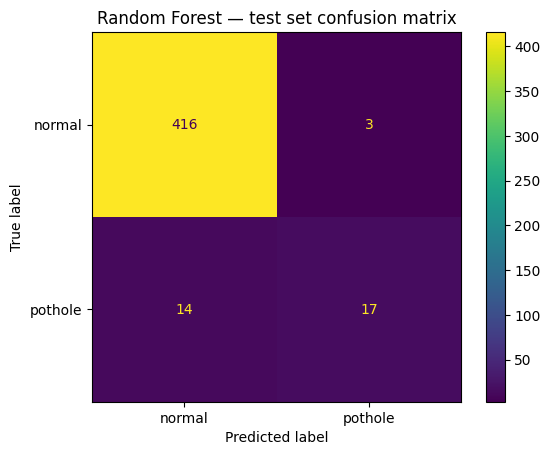

ROC-AUC: 0.930


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
threshold = 0.50
predictions = (probabilities >= threshold).astype(int)

print("Classification report:")
print(classification_report(y_test, predictions, target_names=["normal", "pothole"], zero_division=0))

print("Confusion matrix:")
cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm, display_labels=["normal", "pothole"]).plot()
plt.title("Random Forest — test set confusion matrix")
plt.show()

if len(np.unique(y_test)) == 2:
    print(f"ROC-AUC: {roc_auc_score(y_test, probabilities):.3f}")


In [34]:
all_probabilities = model.predict_proba(X)[:, 1]
data["pothole_probability"] = all_probabilities
data["predicted_pothole"] = (data["pothole_probability"] >= threshold).astype(int)

def group_consecutive_events(frame, max_gap_samples=5):
    """Group nearby positive samples into event candidates."""
    positive_indices = np.flatnonzero(frame["predicted_pothole"].to_numpy() == 1)
    if len(positive_indices) == 0:
        return []

    groups = [[positive_indices[0]]]
    for idx in positive_indices[1:]:
        if idx - groups[-1][-1] <= max_gap_samples:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    events = []
    for group in groups:
        # Use the sample with the highest model probability as the event location.
        peak_idx = max(group, key=lambda i: frame.loc[i, "pothole_probability"])
        events.append({
            "start_time": float(frame.loc[group[0], "timestamp"]),
            "end_time": float(frame.loc[group[-1], "timestamp"]),
            "peak_time": float(frame.loc[peak_idx, "timestamp"]),
            "x": float(frame.loc[peak_idx, "x"]),
            "y": float(frame.loc[peak_idx, "y"]),
            "probability": float(frame.loc[peak_idx, "pothole_probability"]),
            "samples": len(group)
        })
    return events

detected_events = group_consecutive_events(data)
events_df = pd.DataFrame(detected_events)

print(f"Detected event candidates: {len(events_df)}")
display(events_df)


Detected event candidates: 7


,start_time,end_time,peak_time,x,y,probability,samples
0,8.2,8.5,8.2,303.713764,668.133990,0.598831,3
1,21.9,24.6,23.4,301.329522,627.601874,1.000000,27
2,54.7,57.0,55.7,312.187468,542.539225,1.000000,21
3,74.7,74.9,74.7,321.907141,492.725903,0.602283,3
4,87.2,89.3,88.1,328.762068,457.594401,1.000000,21
5,128.4,130.5,129.3,351.144311,349.850601,1.000000,20
6,157.1,159.5,158.3,328.927666,290.579791,1.000000,24


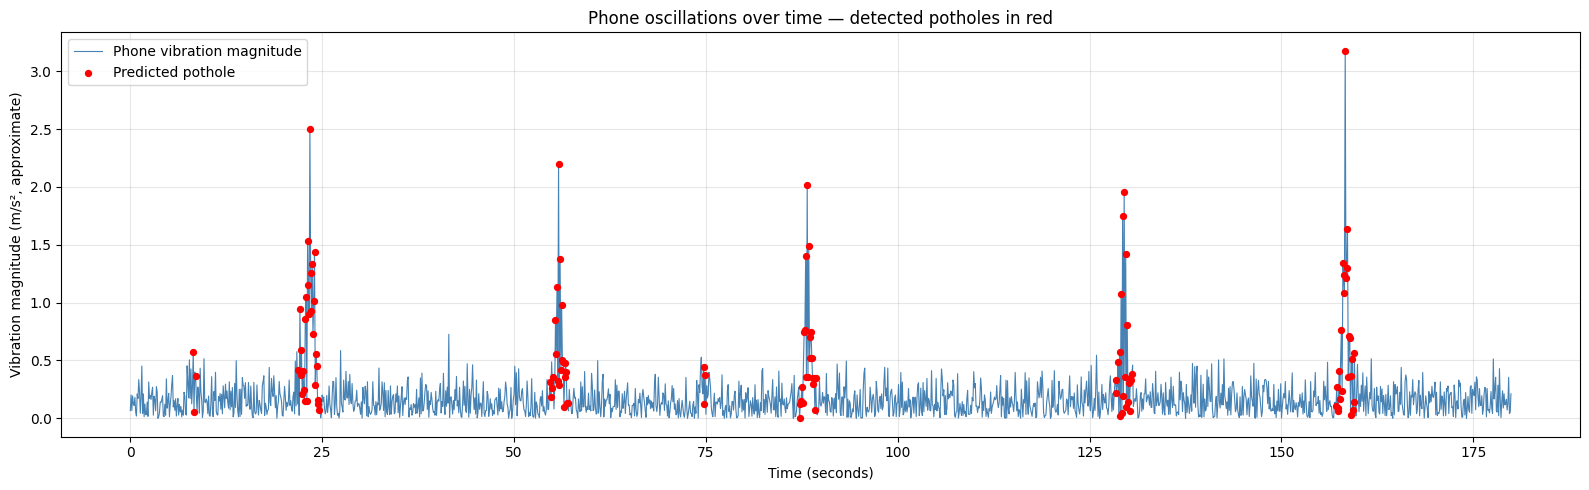

In [35]:
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(data["timestamp"], data["vibration"], color="steelblue", linewidth=0.8,
        label="Phone vibration magnitude")

predicted = data["predicted_pothole"] == 1
ax.scatter(
    data.loc[predicted, "timestamp"],
    data.loc[predicted, "vibration"],
    color="red", s=18, label="Predicted pothole", zorder=3
)

ax.set_title("Phone oscillations over time — detected potholes in red")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Vibration magnitude (m/s², approximate)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


Detected pothole candidates: 7


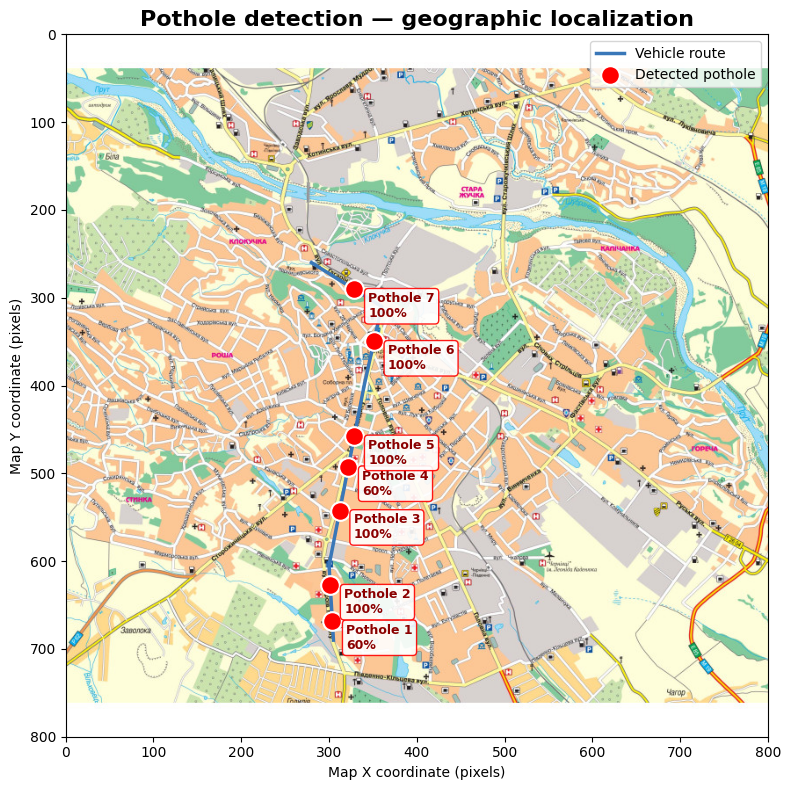

Map loaded from: C:\personal\sci\nlp-fuzzy\src\potholes\city_map.jpg


In [36]:
# Load an existing city map PNG and display detected pothole candidates over it.

map_file = OUTPUT_DIR / "city_map.jpg"  # Change to your existing PNG filename.

# ---------------------------------------------------------
# 1. Load the existing PNG image
# ---------------------------------------------------------

map_image = plt.imread(map_file)

# Get actual image dimensions.
image_height, image_width = map_image.shape[:2]

fig, ax = plt.subplots(figsize=(14, 8))

ax.imshow(
    map_image,
    extent=[0, image_width, image_height, 0],
    aspect="auto",
    zorder=1
)

# ---------------------------------------------------------
# 2. Draw the vehicle route
# ---------------------------------------------------------

ax.plot(
    route_waypoints[:, 0],
    route_waypoints[:, 1],
    color="#3977b8",
    linewidth=2.5,
    label="Vehicle route",
    zorder=3
)

# ---------------------------------------------------------
# 3. Display detected pothole candidates
# ---------------------------------------------------------

if not events_df.empty:

    # Each event is represented by its highest-probability point.
    ax.scatter(
        events_df["x"],
        events_df["y"],
        color="red",
        edgecolors="white",
        linewidths=1.5,
        s=180,
        marker="o",
        label="Detected pothole",
        zorder=10
    )

    # Add event numbers and detection probabilities.
    for event_id, (_, event) in enumerate(events_df.iterrows(), start=1):

        ax.annotate(
            f"Pothole {event_id}\n{event['probability']:.0%}",
            xy=(event["x"], event["y"]),
            xytext=(10, -20),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="darkred",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="red",
                alpha=0.9
            ),
            zorder=11
        )

    print(f"Detected pothole candidates: {len(events_df)}")

else:
    print("No pothole candidates detected.")

# ---------------------------------------------------------
# 4. Final visualization
# ---------------------------------------------------------

ax.set_xlim(0, image_width)
ax.set_ylim(image_height, 0)
ax.set_aspect("equal")

ax.set_title(
    "Pothole detection — geographic localization",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Map X coordinate (pixels)")
ax.set_ylabel("Map Y coordinate (pixels)")

ax.legend(loc="upper right", fontsize=10)
ax.grid(False)

plt.tight_layout()
plt.show()

print(f"Map loaded from: {map_file.resolve()}")

In [37]:
true_locations = data.iloc[pothole_indices][["timestamp", "x", "y"]].copy()
true_locations = true_locations.sort_values("timestamp").reset_index(drop=True)

print("Synthetic ground-truth pothole centres:")
display(true_locations)

print("Model-detected event candidates:")
display(events_df if not events_df.empty else pd.DataFrame(columns=[
    "start_time", "end_time", "peak_time", "x", "y", "probability", "samples"
]))


Synthetic ground-truth pothole centres:


,timestamp,x,y
0,23.4,301.329522,627.601874
1,55.8,312.238624,542.277050
2,88.2,328.813224,457.332226
3,129.5,351.260204,349.329084
4,158.3,328.927666,290.579791


Model-detected event candidates:


,start_time,end_time,peak_time,x,y,probability,samples
0,8.2,8.5,8.2,303.713764,668.133990,0.598831,3
1,21.9,24.6,23.4,301.329522,627.601874,1.000000,27
2,54.7,57.0,55.7,312.187468,542.539225,1.000000,21
3,74.7,74.9,74.7,321.907141,492.725903,0.602283,3
4,87.2,89.3,88.1,328.762068,457.594401,1.000000,21
5,128.4,130.5,129.3,351.144311,349.850601,1.000000,20
6,157.1,159.5,158.3,328.927666,290.579791,1.000000,24


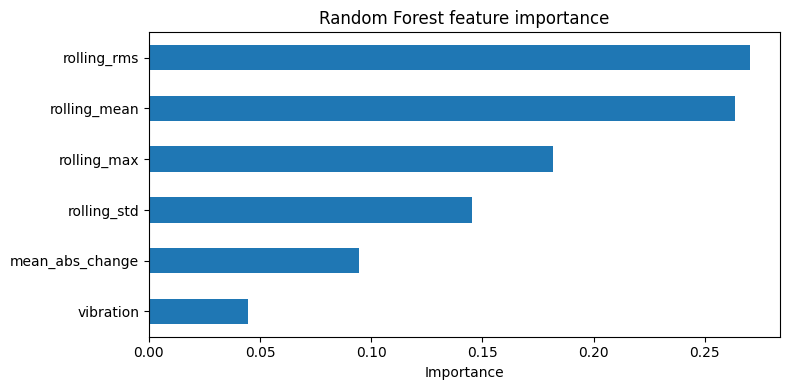

In [38]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [39]:
events_file = OUTPUT_DIR / "detected_pothole_candidates.json"

with open(events_file, "w", encoding="utf-8") as f:
    json.dump(detected_events, f, indent=2)

print(f"Saved event candidates to: {events_file.resolve()}")


Saved event candidates to: C:\personal\sci\nlp-fuzzy\src\potholes\detected_pothole_candidates.json
